# MPC-Lauf in der Simulation auswerten (ros2 bag)

Liest eine Aufnahme, die mit

```bash
ros2 bag record --use-sim-time --all -o sim_mpc_run_01
```

gemacht wurde, und wertet aus:

- Raten der Topics (Sim-Zeit)
- Rechenzeit des MPC (`/mpc/timing`: `data[0]` = solve_ms, `data[1]` = period_ms)
- Bahn in World und Abstand zum Referenzpfad
- Lenk- und Geschwindigkeitsbefehle

**Installation (einmalig, NumPy festhalten):**

```bash
pip install --user rosbags "numpy==1.26.4"
python3 -c "import numpy; print(numpy.__version__)"   # muss 1.26.4 bleiben
```

## 1. Einstellungen
`BAG_PATH` = Bag-Ordner (`-o` beim Aufnehmen). Der Referenzpfad kommt aus dem Topic `/debug/waypoints` in der Bag; `WAYPOINT_FILE` ist nur die Rückfallebene, falls das Topic fehlt.

In [15]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from rosbags.highlevel import AnyReader
from rosbags.typesys import Stores, get_typestore

# ---- settings ---------------------------------------------------------------
# folder created by "ros2 bag record -o"
BAG_PATH = Path(
    "/home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/"
    "sim-to-real-gap/stage-2-testing/data-sim-athena/sim_mpc_h12_ts008_run01"
)
# reference path as published by the MPC node (read from the bag)
WAYPOINT_TOPIC = "/debug/waypoints"
# fallback only if the topic is missing in the bag: path to the waypoint YAML, else None
WAYPOINT_FILE = None
MPC_PERIOD_MS = 25.0  # timer period of mpc_callback
STEERING_LIMIT = 0.26  # delta bound in MPC.py

print(f"reading bag:       {BAG_PATH}")
print(f"waypoints from:    topic {WAYPOINT_TOPIC} (fallback file: {WAYPOINT_FILE})")

reading bag:       /home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/sim-to-real-gap/stage-2-testing/data-sim-athena/sim_mpc_h12_ts008_run01
waypoints from:    topic /debug/waypoints (fallback file: None)


## 2. Hilfsfunktionen

In [16]:
def yaw_from_quaternion(q):
    """Return the yaw angle of a quaternion."""
    siny_cosp = 2.0 * (q.w * q.z + q.x * q.y)
    cosy_cosp = 1.0 - 2.0 * (q.y**2 + q.z**2)
    return math.atan2(siny_cosp, cosy_cosp)


def read_topic(reader, topic):
    """Return a list of (time_s, msg) for one topic. time_s = bag time (sim time)."""
    connections = []
    for connection in reader.connections:
        if connection.topic == topic:
            connections.append(connection)
    result = []
    if not connections:
        print(f"!! topic {topic} not found in bag")
        return result
    for connection, timestamp, rawdata in reader.messages(connections=connections):
        msg = reader.deserialize(rawdata, connection.msgtype)
        result.append((timestamp / 1e9, msg))
    return result


def points_from_message(msg):
    """Return an (N, 2) array of x, y from a Marker, MarkerArray or Path message."""
    xy = []
    if hasattr(msg, "markers"):  # visualization_msgs/MarkerArray
        for marker in msg.markers:
            if len(marker.points) > 0:
                for point in marker.points:
                    xy.append([point.x, point.y])
            else:
                xy.append([marker.pose.position.x, marker.pose.position.y])
    elif hasattr(msg, "poses"):  # nav_msgs/Path
        for pose_stamped in msg.poses:
            xy.append([pose_stamped.pose.position.x, pose_stamped.pose.position.y])
    elif hasattr(msg, "points"):  # visualization_msgs/Marker (LINE_STRIP, POINTS, ...)
        for point in msg.points:
            xy.append([point.x, point.y])
    return np.array(xy, dtype=float)


def frame_of_message(msg):
    """Return the frame_id of a Marker, MarkerArray or Path message."""
    if hasattr(msg, "markers"):
        if len(msg.markers) > 0:
            return msg.markers[0].header.frame_id
        return ""
    return msg.header.frame_id


def rate_hz(times):
    """Median message rate in Hz from a list of times in seconds."""
    if len(times) < 2:
        return float("nan")
    return 1.0 / np.median(np.diff(times))

## 3. Bag lesen
Zeigt alle Topics in der Aufnahme und liest die benötigten.

In [17]:
typestore = get_typestore(Stores.ROS2_JAZZY)
with AnyReader([BAG_PATH], default_typestore=typestore) as reader:
    print("topics in bag:")
    for connection in reader.connections:
        print(f"  {connection.topic:28s} {connection.msgtype:45s} {connection.msgcount:6d} msgs")
    odom_msgs = read_topic(reader, "/odom")
    cmd_msgs = read_topic(reader, "/ackermann_cmd")
    timing_msgs = read_topic(reader, "/mpc/timing")
    tf_msgs = read_topic(reader, "/tf")
    waypoint_msgs = read_topic(reader, WAYPOINT_TOPIC)

topics in bag:
  /ackermann_cmd               ackermann_msgs/msg/AckermannDriveStamped        2115 msgs
  /debug/waypoints             visualization_msgs/msg/Marker                      1 msgs
  /clicked_point               geometry_msgs/msg/PointStamped                     0 msgs
  /tf                          tf2_msgs/msg/TFMessage                          2324 msgs
  /events/write_split          rosbag2_interfaces/msg/WriteSplitEvent             0 msgs
  /clock                       rosgraph_msgs/msg/Clock                         2324 msgs
  /initialpose                 geometry_msgs/msg/PoseWithCovarianceStamped        0 msgs
  /move_base_simple/goal       geometry_msgs/msg/PoseStamped                      0 msgs
  /parameter_events            rcl_interfaces/msg/ParameterEvent                  0 msgs
  /odom                        nav_msgs/msg/Odometry                           2324 msgs
  /rosout                      rcl_interfaces/msg/Log                          2214 msgs
  /rtf

## 4. Daten aufbereiten

- `World -> odom` (Startpose) aus dem ersten passenden `/tf`-Eintrag
- Pose aus `/odom` in World umrechnen (gleiche Rechnung wie im MPC-Callback)
- Befehle und MPC-Timing als Arrays
- Abstand der gefahrenen Bahn zum Referenzpfad (Pfad auf 1 cm verdichtet)

In [18]:
# ---- World -> odom (start pose), first occurrence in /tf ---------------------
world_to_odom = None
for time_s, msg in tf_msgs:
    for transform in msg.transforms:
        if transform.header.frame_id == "World" and transform.child_frame_id == "odom":
            world_to_odom = (
                transform.transform.translation.x,
                transform.transform.translation.y,
                yaw_from_quaternion(transform.transform.rotation),
            )
            break
    if world_to_odom is not None:
        break
# fallback if /tf is missing in the bag: enter the start pose by hand
# world_to_odom = (3.25, 5.4, -math.pi / 2)
print(f"World -> odom: {world_to_odom}")
odom_x0, odom_y0, odom_yaw0 = world_to_odom

# ---- odometry -> pose in World ----------------------------------------------
t_odom, x_world, y_world, psi_world, v_odom = [], [], [], [], []
for time_s, msg in odom_msgs:
    x_o = msg.pose.pose.position.x
    y_o = msg.pose.pose.position.y
    psi_o = yaw_from_quaternion(msg.pose.pose.orientation)
    t_odom.append(time_s)
    x_world.append(odom_x0 + math.cos(odom_yaw0) * x_o - math.sin(odom_yaw0) * y_o)
    y_world.append(odom_y0 + math.sin(odom_yaw0) * x_o + math.cos(odom_yaw0) * y_o)
    psi_sum = odom_yaw0 + psi_o
    psi_world.append(math.atan2(math.sin(psi_sum), math.cos(psi_sum)))
    v_odom.append(msg.twist.twist.linear.x)
t_odom = np.array(t_odom)
x_world = np.array(x_world)
y_world = np.array(y_world)
psi_world = np.array(psi_world)
v_odom = np.array(v_odom)

# ---- commands ---------------------------------------------------------------
t_cmd = np.array([time_s for time_s, msg in cmd_msgs])
steer_cmd = np.array([msg.drive.steering_angle for time_s, msg in cmd_msgs])
speed_cmd = np.array([msg.drive.speed for time_s, msg in cmd_msgs])

# ---- MPC timing: data[0] = solve_ms, data[1] = period_ms ---------------------
t_timing = np.array([time_s for time_s, msg in timing_msgs])
solve_ms = np.array([msg.data[0] for time_s, msg in timing_msgs])
period_ms = np.array([msg.data[1] for time_s, msg in timing_msgs])
t_period = t_timing[1:]
period_ms = period_ms[1:]  # first value is 0 (no previous call)

# common time axis: start at the first odometry message
t0 = t_odom[0]

# ---- reference path: from the waypoint topic, fallback YAML -----------------
if len(waypoint_msgs) > 0:
    first_time, first_msg = waypoint_msgs[0]
    waypoints = points_from_message(first_msg)
    print(
        f"waypoints from topic {WAYPOINT_TOPIC}: {len(waypoints)} points, "
        f"frame '{frame_of_message(first_msg)}' (must be World)"
    )
elif WAYPOINT_FILE is not None:
    with open(WAYPOINT_FILE, "r") as file:
        waypoints = np.array(yaml.safe_load(file)["waypoints"], dtype=float)
    print(f"waypoints from file {WAYPOINT_FILE}: {len(waypoints)} points")
else:
    raise RuntimeError(f"no waypoints: topic {WAYPOINT_TOPIC} not in bag and WAYPOINT_FILE is None")

# ---- distance to the reference path -----------------------------------------

# densify the polyline (1 cm) so the nearest point is close to the true projection
dense_points = []
for i in range(len(waypoints) - 1):
    start = waypoints[i]
    end = waypoints[i + 1]
    n_steps = max(1, int(np.linalg.norm(end - start) / 0.01))
    for k in range(n_steps):
        dense_points.append(start + (end - start) * k / n_steps)
dense_points = np.array(dense_points)

car_xy = np.column_stack([x_world, y_world])
distance_to_path = np.empty(len(car_xy))
for i in range(len(car_xy)):
    distance_to_path[i] = np.min(np.linalg.norm(dense_points - car_xy[i], axis=1))

print(f"odom: {len(t_odom)} msgs, cmd: {len(t_cmd)} msgs, timing: {len(t_timing)} msgs")
print(f"sim time covered: {t_odom[-1] - t0:.1f} s")

World -> odom: (3.25, 5.4, -1.5707771464270195)
waypoints from topic /debug/waypoints: 1060 points, frame 'World' (must be World)
odom: 2324 msgs, cmd: 2115 msgs, timing: 2115 msgs
sim time covered: 38.7 s


## 5. Kennzahlen

In [19]:
print("--- rates (sim time) ---")
print(f"/odom:          {rate_hz(t_odom):6.1f} Hz")
print(f"/ackermann_cmd: {rate_hz(t_cmd):6.1f} Hz")
print(f"/mpc/timing:    {rate_hz(t_timing):6.1f} Hz")

print("\n--- MPC timing (wall time) ---")
print(
    f"solve  mean {solve_ms.mean():6.1f} ms   p95 {np.percentile(solve_ms, 95):6.1f} ms   "
    f"max {solve_ms.max():6.1f} ms   > {MPC_PERIOD_MS:.0f} ms: "
    f"{np.mean(solve_ms > MPC_PERIOD_MS) * 100:5.1f} %"
)
print(
    f"period mean {period_ms.mean():6.1f} ms   p95 {np.percentile(period_ms, 95):6.1f} ms   "
    f"max {period_ms.max():6.1f} ms"
)

print("\n--- tracking ---")
print(
    f"distance to path: mean {distance_to_path.mean() * 100:5.1f} cm   "
    f"p95 {np.percentile(distance_to_path, 95) * 100:5.1f} cm   "
    f"max {distance_to_path.max() * 100:5.1f} cm"
)
print(
    f"steering at limit (|delta| >= {STEERING_LIMIT - 0.005:.3f}): "
    f"{np.mean(np.abs(steer_cmd) >= STEERING_LIMIT - 0.005) * 100:5.1f} % of commands"
)
print(f"speed: mean measured {v_odom.mean():.2f} m/s, mean commanded {speed_cmd.mean():.2f} m/s")

--- rates (sim time) ---
/odom:            60.0 Hz
/ackermann_cmd:   60.0 Hz
/mpc/timing:      60.0 Hz

--- MPC timing (wall time) ---
solve  mean   20.0 ms   p95   22.4 ms   max 5049.5 ms   > 25 ms:   1.4 %
period mean   27.6 ms   p95   27.5 ms   max 5053.9 ms

--- tracking ---
distance to path: mean   8.3 cm   p95  23.0 cm   max  28.0 cm
steering at limit (|delta| >= 0.255):  58.4 % of commands
speed: mean measured 0.64 m/s, mean commanded 0.77 m/s


## 6. Plots

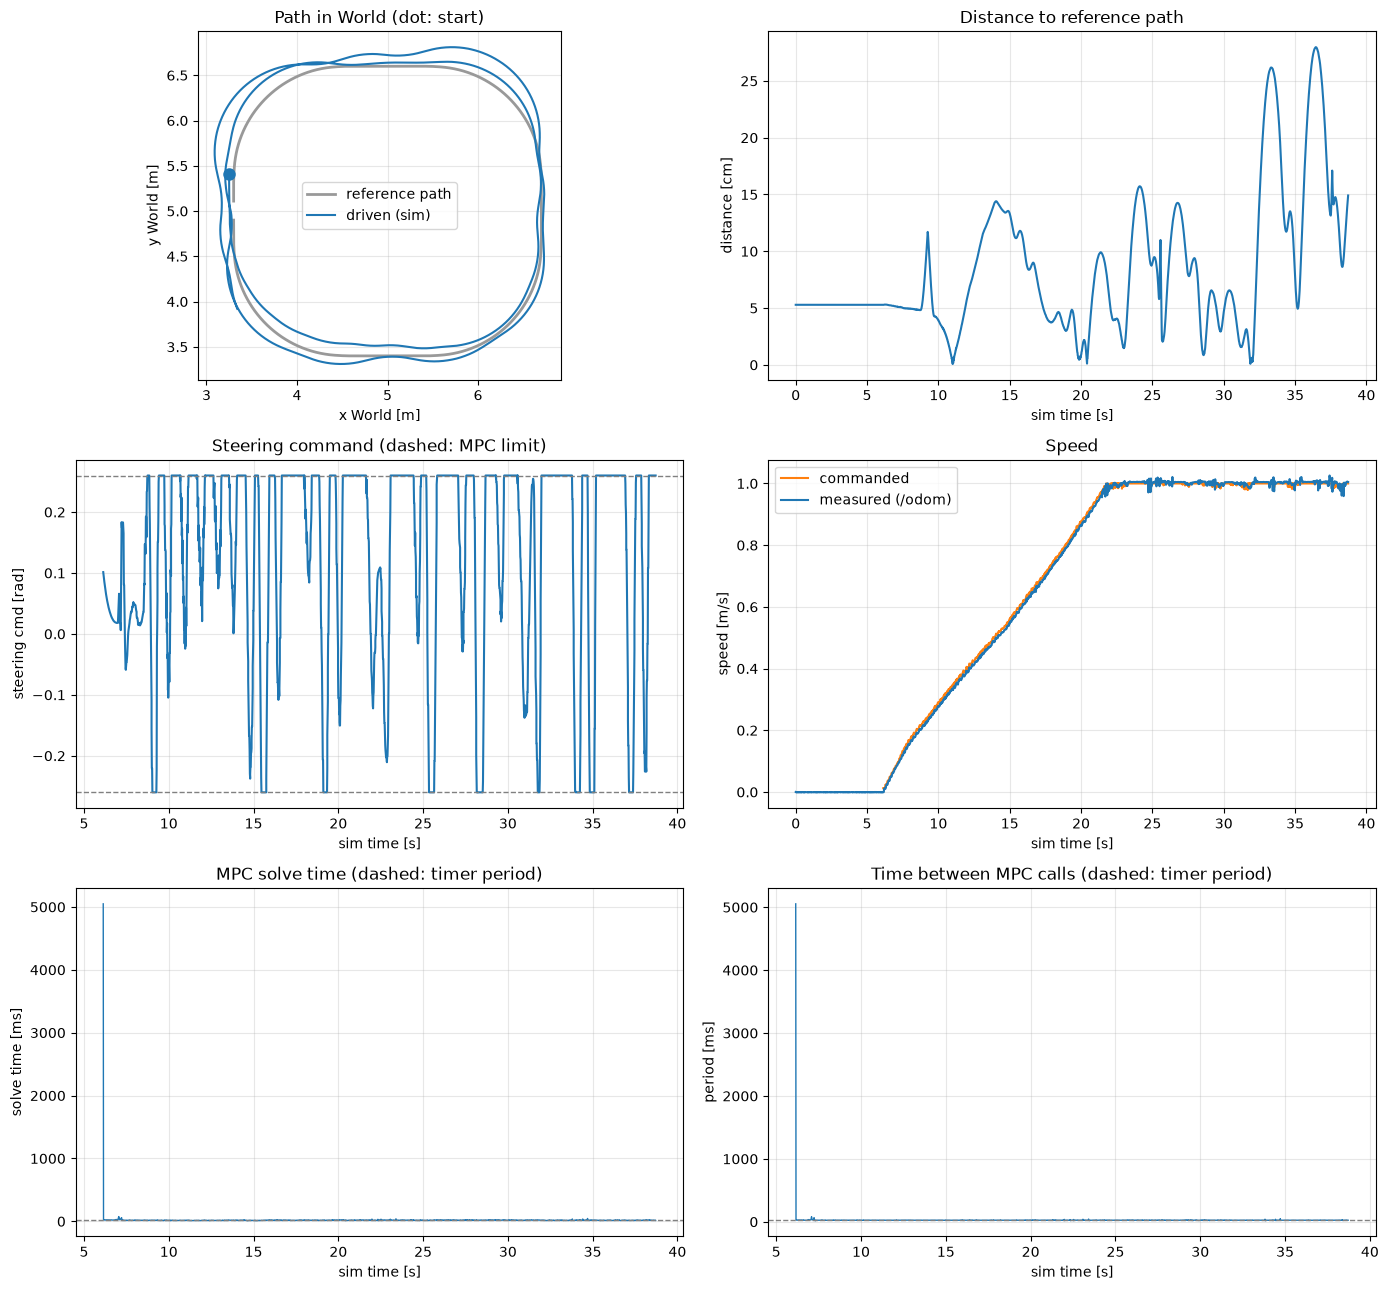

In [20]:
fig, axes = plt.subplots(3, 2, figsize=(14, 13))

ax = axes[0, 0]
ax.plot(waypoints[:, 0], waypoints[:, 1], color="0.6", linewidth=2, label="reference path")
ax.plot(x_world, y_world, color="tab:blue", linewidth=1.5, label="driven (sim)")
ax.plot(x_world[0], y_world[0], "o", color="tab:blue", markersize=8)
ax.set_aspect("equal")
ax.set_xlabel("x World [m]")
ax.set_ylabel("y World [m]")
ax.set_title("Path in World (dot: start)")
ax.legend()

ax = axes[0, 1]
ax.plot(t_odom - t0, distance_to_path * 100, color="tab:blue", linewidth=1.5)
ax.set_xlabel("sim time [s]")
ax.set_ylabel("distance [cm]")
ax.set_title("Distance to reference path")

ax = axes[1, 0]
ax.plot(t_cmd - t0, steer_cmd, color="tab:blue", linewidth=1.5)
ax.axhline(STEERING_LIMIT, color="0.5", linestyle="--", linewidth=1)
ax.axhline(-STEERING_LIMIT, color="0.5", linestyle="--", linewidth=1)
ax.set_xlabel("sim time [s]")
ax.set_ylabel("steering cmd [rad]")
ax.set_title("Steering command (dashed: MPC limit)")

ax = axes[1, 1]
ax.plot(t_cmd - t0, speed_cmd, color="tab:orange", linewidth=1.5, label="commanded")
ax.plot(t_odom - t0, v_odom, color="tab:blue", linewidth=1.5, label="measured (/odom)")
ax.set_xlabel("sim time [s]")
ax.set_ylabel("speed [m/s]")
ax.set_title("Speed")
ax.legend()

ax = axes[2, 0]
ax.plot(t_timing - t0, solve_ms, color="tab:blue", linewidth=1)
ax.axhline(MPC_PERIOD_MS, color="0.5", linestyle="--", linewidth=1)
ax.set_xlabel("sim time [s]")
ax.set_ylabel("solve time [ms]")
ax.set_title("MPC solve time (dashed: timer period)")

ax = axes[2, 1]
ax.plot(t_period - t0, period_ms, color="tab:blue", linewidth=1)
ax.axhline(MPC_PERIOD_MS, color="0.5", linestyle="--", linewidth=1)
ax.set_xlabel("sim time [s]")
ax.set_ylabel("period [ms]")
ax.set_title("Time between MPC calls (dashed: timer period)")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.ticklabel_format(axis="y", useOffset=False)  # no "+3e-1" offset on the axis

plt.tight_layout()
plt.show()